# Notebook 22: Integración de Aeromagnetometría Cortical Invariante (EMAG2v3 / IGN) y Reentrenamiento Multigeofísico

## 1. Contexto y Diagnóstico de la Capa Descargada
En la solicitud previa se inspeccionó el archivo [`magnetometriaradiometria.gpkg`](file:///c:/Users/Lenovo/Desktop/PROYECTO%20IA/GeoAI/GeoAI/magnetometriaradiometria.gpkg) del SIGEOF (IGME). El análisis reveló que este archivo correspondía a la **capa índice de líneas de vuelo vectoriales (`MultiLineString`)**, la cual contiene los metadatos de las campañas históricas (`ID_LINE`, `VALU_LINE`, `NAME_VUELO`), pero **carece de las mediciones cuantitativas de campo magnético (nT) y radiometría**.

Para solventar esta limitación y dotar al modelo de información geofísica magnética continua en el 100% del territorio peninsular (sin huecos ni sesgos geográficos), se implementa la **Opción A**:
- Integración de la malla continua de **Anomalía Magnética de la Corteza (EMAG2v3 NOAA/IGN)** en unidades físicas reales de nanoTeslas ($\text{nT}$), con resolución de 2 minutos de arco interpolada a la malla nacional de $1\times1\text{ km}$ ($478.443\text{ celdas}$).
- Imputación espacial rigurosa de las celdas periféricas costeras mediante vecinos más cercanos ponderados con `cKDTree`.
- Derivación de **variables magnéticas invariantes a la traslación espacial**:
  1. **`magnetometria_gradiente`**: Magnitud del gradiente magnético horizontal ($|\nabla M|$ en $\text{nT/km}$), que delinea fallas, zonas de cizalla y bordes de intrusiones ígneas.
  2. **`magnetometria_residual_local_zscore`**: Anomalía magnética somera normalizada respecto a una ventana móvil de $25\text{ km}$, que detecta zonas locales de desmagnetización hidrotermal (destrucción de magnetita por fluidos mineralizantes auríferos).
- Integración multigeofísica completa: **Geología de Superficie + Gravimetría Invariante + Aeromagnetometría Invariante** (75 covariables).
- Reentrenamiento del ensamble nacional LightGBM de 8 miembros con regularización anti-monopolio (`colsample_bytree = 0.7`, `min_child_samples = 15`) y evaluación en validación cruzada ciega de 7 rotaciones.

In [1]:
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
import pyproj
import rasterio
from scipy.ndimage import gaussian_filter, sobel
from scipy.spatial import cKDTree
import lightgbm as lgb
from sklearn.pipeline import Pipeline

from geoau.geochemical_experiment import load_data, make_preprocessor, predict, select_sample
from geoau.national_evaluation import deposit_metrics, PERCENTAGES

ROOT = Path("..").resolve() if Path("..").resolve().name == "GeoAI" and not Path("data").exists() else Path(".").resolve()
if (ROOT / "GeoAI").exists():
    ROOT = ROOT / "GeoAI"

print(f"Raíz del repositorio: {ROOT}")
print(f"Métricas registradas en national_evaluation.PERCENTAGES: {PERCENTAGES}")

Raíz del repositorio: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI
Métricas registradas en national_evaluation.PERCENTAGES: (1, 5, 10, 20)


## 2. Inspección y Diagnóstico del Fichero `magnetometriaradiometria.gpkg`

Documentamos la estructura interna del archivo descargado del SIGEOF para verificar por qué no puede usarse directamente como predictor magnético cuantitativo.

In [2]:
mag_gpkg = ROOT / "magnetometriaradiometria.gpkg"
if mag_gpkg.is_file():
    info_mag = pyogrio.read_info(mag_gpkg)
    df_mag_head = pyogrio.read_dataframe(mag_gpkg, max_features=5)
    print("=== Inspección Técnica de magnetometriaradiometria.gpkg ===")
    print(f"  Tamaño de archivo : {mag_gpkg.stat().st_size / (1024*1024):.2f} MB")
    print(f"  Geometría         : {info_mag['geometry_type']} ({info_mag['features']:,} entidades)")
    print(f"  Sistema (CRS)     : {info_mag['crs']}")
    print(f"  Campos de atributos: {info_mag['fields'].tolist()}")
    print("\nPrimeros registros:")
    display(df_mag_head)
    print("\n⚠️ Diagnóstico: El archivo contiene exclusivamente las trazas de vuelo (MultiLineString).")
    print("   No contiene lecturas cuantitativas de nanoTeslas (nT) ni cuentas radiométricas.")
else:
    print("magnetometriaradiometria.gpkg no encontrado.")

=== Inspección Técnica de magnetometriaradiometria.gpkg ===
  Tamaño de archivo : 73.60 MB
  Geometría         : MultiLineString (3,811 entidades)
  Sistema (CRS)     : EPSG:25830
  Campos de atributos: ['ID_LINE', 'VALU_LINE', 'DATE_LINE', 'NAME_VUELO']

Primeros registros:


,ID_LINE,VALU_LINE,DATE_LINE,NAME_VUELO,geometry
0,1,230010,800101,Zona 2,"MULTILINESTRING ((271330.711 4419233.717, 2713..."
1,2,230020,800101,Zona 2,"MULTILINESTRING ((271210.718 4420353.72, 27123..."
2,3,230030,800101,Zona 2,"MULTILINESTRING ((276120.638 4413283.67, 27610..."
3,4,230040,800101,Zona 2,"MULTILINESTRING ((270770.747 4425143.732, 2708..."
4,5,230050,800101,Zona 2,"MULTILINESTRING ((277840.629 4414113.664, 2778..."



⚠️ Diagnóstico: El archivo contiene exclusivamente las trazas de vuelo (MultiLineString).
   No contiene lecturas cuantitativas de nanoTeslas (nT) ni cuentas radiométricas.


## 3. Ingesta y Derivación de la Anomalía Magnética Continua (EMAG2v3 / IGN)

Extraemos la anomalía magnética de la corteza (en nanoTeslas, $\text{nT}$) para las $478.443\text{ celdas}$ de la malla territorial:
1. Proyección de coordenadas `EPSG:25830` a longitud/latitud `EPSG:4326`.
2. Muestreo de la cuadrícula global EMAG2v3 (2 minutos de arco de resolución) a altitud constante.
3. Imputación de celdas nodata litorales mediante vecinos más cercanos espaciales (`cKDTree`).
4. Cálculo del gradiente horizontal de Bouguer magnético ($|\nabla M|$ en $\text{nT/km}$) y del Z-score relativo local.

In [3]:
t_mag = time.time()
data = load_data(ROOT)
grid = data.grid.copy()
print(f"Malla territorial cargada: {len(grid):,} celdas")

# 1. Transformar coordenadas a WGS84 (lon, lat)
transformer = pyproj.Transformer.from_crs('EPSG:25830', 'EPSG:4326', always_xy=True)
lons, lats = transformer.transform(grid['x_center'].values, grid['y_center'].values)

# 2. Leer las ventanas de España desde el GeoTIFF científico EMAG2v3
url_emag = '/vsicurl/https://www.ngdc.noaa.gov/geomag/data/EMAG2/EMAG2_V3_UpCont_DataTiff.tif'
with rasterio.open(url_emag) as src:
    inv = ~src.transform
    cols, rows = inv * (np.where(lons < 0, lons + 360.0, lons), lats)
    cols = np.clip(np.round(cols).astype(int), 0, src.width - 1)
    rows = np.clip(np.round(rows).astype(int), 0, src.height - 1)
    
    w_rmin, w_rmax = rows.min() - 2, rows.max() + 2
    w_cmin_west, w_cmax_west = cols[lons < 0].min() - 2, cols[lons < 0].max() + 2
    w_cmin_east, w_cmax_east = cols[lons >= 0].min() - 2, cols[lons >= 0].max() + 2
    
    win_west = rasterio.windows.Window(w_cmin_west, w_rmin, w_cmax_west - w_cmin_west + 1, w_rmax - w_rmin + 1)
    win_east = rasterio.windows.Window(w_cmin_east, w_rmin, w_cmax_east - w_cmin_east + 1, w_rmax - w_rmin + 1)
    
    arr_west = src.read(1, window=win_west)
    arr_east = src.read(1, window=win_east)
    
    mag_vals = np.empty(len(grid), dtype='float32')
    mask_west = lons < 0
    mag_vals[mask_west] = arr_west[rows[mask_west] - w_rmin, cols[mask_west] - w_cmin_west]
    mask_east = ~mask_west
    mag_vals[mask_east] = arr_east[rows[mask_east] - w_rmin, cols[mask_east] - w_cmin_east]

# 3. Imputación de celdas litorales (nodata < -1000 nT) mediante cKDTree
is_nodata = mag_vals < -1000.0
n_nodata = is_nodata.sum()
if n_nodata > 0:
    valid_coords = grid.loc[~is_nodata, ['x_center', 'y_center']].to_numpy()
    valid_vals = mag_vals[~is_nodata]
    tree = cKDTree(valid_coords)
    nodata_coords = grid.loc[is_nodata, ['x_center', 'y_center']].to_numpy()
    _, nn_idx = tree.query(nodata_coords, k=1)
    mag_vals[is_nodata] = valid_vals[nn_idx]

grid['magnetometria_anomalia'] = mag_vals
print(f"Celdas imputadas espacialmente: {n_nodata:,} ({n_nodata/len(grid)*100:.2f}%)")
print(f"Valores nulos remanentes: {grid['magnetometria_anomalia'].isna().sum()}")

# 4. Ráster 2D para gradiente Sobel y Z-score local
max_row, max_col = int(grid['row'].max() + 1), int(grid['col'].max() + 1)
raster_mag = np.full((max_row, max_col), np.nan, dtype='float32')
raster_mag[grid['row'].to_numpy(), grid['col'].to_numpy()] = grid['magnetometria_anomalia']
mean_m = float(np.nanmean(raster_mag))
raster_filled = np.where(np.isnan(raster_mag), mean_m, raster_mag)

# Gradiente horizontal de anomalía magnética (nT/km)
gx = sobel(raster_filled, axis=1) / 8.0
gy = sobel(raster_filled, axis=0) / 8.0
grid['magnetometria_gradiente'] = np.hypot(gx, gy)[grid['row'].to_numpy(), grid['col'].to_numpy()].astype('float32')

# Z-Score local del residual magnético (ventana móvil sigma = 25 km)
mean_smooth = gaussian_filter(raster_filled, sigma=25.0)
sq_smooth = gaussian_filter(raster_filled**2, sigma=25.0)
local_std = np.sqrt(np.maximum(sq_smooth - mean_smooth**2, 1e-4))
grid['magnetometria_residual_local_zscore'] = np.clip(((raster_filled - mean_smooth) / local_std)[grid['row'].to_numpy(), grid['col'].to_numpy()], -3.0, 3.0).astype('float32')

print(f"✅ Variables magnéticas calculadas e imputadas en {time.time() - t_mag:.1f}s")
mag_cols = ['magnetometria_anomalia', 'magnetometria_gradiente', 'magnetometria_residual_local_zscore']
display(grid[mag_cols].describe().round(3))

Malla territorial cargada: 478,443 celdas


Celdas imputadas espacialmente: 23,759 (4.97%)
Valores nulos remanentes: 0


✅ Variables magnéticas calculadas e imputadas en 15.2s


,magnetometria_anomalia,magnetometria_gradiente,magnetometria_residual_local_zscore
count,478443.000,478443.000,478443.000
mean,1.491,1.183,0.011
std,21.815,2.551,0.677
min,-96.376,0.000,-3.000
25%,-11.137,0.157,-0.450
50%,0.283,0.510,-0.036
75%,12.035,1.189,0.423
max,159.095,85.275,3.000


## 4. Firma Geofísica Magnética de las Mineralizaciones Auríferas

Contrastamos las propiedades magnéticas de las celdas con depósitos e indicios auríferos ($P$) frente al fondo territorial peninsular.

In [4]:
pos_ids = set(data.positives.cell_id)
is_pos = grid.cell_id.isin(pos_ids)

mag_stats = []
for col in mag_cols:
    bg_m = grid.loc[~is_pos, col].mean()
    p_m = grid.loc[is_pos, col].mean()
    diff = p_m - bg_m
    ratio = f"x{p_m/bg_m:.2f}" if bg_m != 0 and abs(bg_m) > 0.05 else f"{diff:+.2f}"
    mag_stats.append({
        'Variable Magnética': col,
        'Media Fondo Nacional': round(bg_m, 3),
        'Media Celdas P (Au)': round(p_m, 3),
        'Diferencia / Ratio': f"{diff:+.2f} nT" if 'anomalia' in col else ratio
    })

df_mag_stats = pd.DataFrame(mag_stats)
display(df_mag_stats)

print("\n💡 Hallazgos Geocientíficos Clave:")
print("1. Desmagnetización / Serie Ilmenita: Las celdas con oro presentan un promedio de anomalía de -7.29 nT frente a +1.50 nT en el fondo nacional.")
print("   Refleja la afinidad por granitoides reducidos de la serie de ilmenita y la alteración hidrotermal de destrucción de magnetita.")
print("2. Gradiente Magnético Horizontal: Es sistemáticamente más elevado (+9%) en las zonas mineralizadas, detectando contrastes de permeabilidad magmática y contactos de fallas mayores.")

,Variable Magnética,Media Fondo Nacional,Media Celdas P (Au),Diferencia / Ratio
0,magnetometria_anomalia,1.504,-7.288,-8.79 nT
1,magnetometria_gradiente,1.182,1.286,x1.09
2,magnetometria_residual_local_zscore,0.011,-0.120,-0.13



💡 Hallazgos Geocientíficos Clave:
1. Desmagnetización / Serie Ilmenita: Las celdas con oro presentan un promedio de anomalía de -7.29 nT frente a +1.50 nT en el fondo nacional.
   Refleja la afinidad por granitoides reducidos de la serie de ilmenita y la alteración hidrotermal de destrucción de magnetita.
2. Gradiente Magnético Horizontal: Es sistemáticamente más elevado (+9%) en las zonas mineralizadas, detectando contrastes de permeabilidad magmática y contactos de fallas mayores.


## 5. Reentrenamiento del Modelo Nacional Multigeofísico (75 Covariables)

Integramos el espacio completo de covariables multigeofísicas:
- **64 covariables base** del modelo nacional original.
- **7 covariables físicas de superficie** (Notebook 20): grado metamórfico, afinidad a esquistos verdes, plutonismo varisco, proximidad térmica, volcanismo neógeno, contraste reológico y trampa estructural.
- **2 covariables gravimétricas invariantes** (Notebook 21): `bouguer_gradiente` y `bouguer_residual_local_zscore`.
- **2 covariables aeromagnéticas invariantes**: `magnetometria_gradiente` y `magnetometria_residual_local_zscore`.

Reentrenamos el ensamble LightGBM Bagging PU de 8 miembros con regularización `colsample_bytree = 0.7` y `min_child_samples = 15`.

In [5]:
# 1. Construir matriz de características enriquecida
X_all = data.features.copy()

# Variables físicas continuas de superficie
grade_weights = {
    'litologia_u000_fraccion': 0.0, 'litologia_u001_fraccion': 1.0, 'litologia_u002_fraccion': 0.0,
    'litologia_u003_fraccion': 0.0, 'litologia_u004_fraccion': 0.0, 'litologia_u005_fraccion': 0.0,
    'litologia_u006_fraccion': 0.0, 'litologia_u007_fraccion': 0.5, 'litologia_u008_fraccion': 2.0,
    'litologia_u009_fraccion': 0.0, 'litologia_u010_fraccion': 3.0, 'litologia_u011_fraccion': 2.5,
    'litologia_u012_fraccion': 0.0, 'litologia_u013_fraccion': 2.0, 'litologia_u014_fraccion': 3.0,
    'litologia_u015_fraccion': 2.5, 'litologia_u016_fraccion': 1.5, 'litologia_u018_fraccion': 1.5,
    'litologia_u019_fraccion': 1.0
}
X_all['grado_metamorfico'] = sum(X_all[col] * w for col, w in grade_weights.items()).astype('float32')
X_all['afinidad_esquistos_verdes'] = np.exp(-((X_all['grado_metamorfico'] - 2.0)**2) / (2 * 0.5**2)).astype('float32')

hercinico = X_all['edades_u000_fraccion'] + X_all['edades_u001_fraccion'] + X_all['edades_u008_fraccion']
granitoides = X_all['litologia_u011_fraccion'] + X_all['litologia_u015_fraccion'] + X_all['litologia_u014_fraccion']
X_all['plutonismo_varisco'] = (granitoides * hercinico).astype('float32')
X_all['prox_termica_varisca'] = (np.exp(-X_all['dist_contacto_intrusivo_cartografiada_m'] / 15000.0) * (hercinico + X_all['edades_u013_fraccion'])).astype('float32')

neogeno = X_all['edades_u011_fraccion'] + X_all['edades_u012_fraccion'] + X_all['edades_u016_fraccion']
X_all['volcanismo_neogeno'] = (X_all['litologia_u019_fraccion'] * neogeno).astype('float32')

f_comp = X_all['litologia_u008_fraccion'] + X_all['litologia_u010_fraccion'] + X_all['litologia_u011_fraccion'] + X_all['litologia_u015_fraccion'] + X_all['litologia_u000_fraccion']
f_incomp = X_all['litologia_u016_fraccion'] + X_all['litologia_u013_fraccion'] + X_all['litologia_u001_fraccion']
X_all['contraste_reologico'] = (4.0 * f_comp * f_incomp).astype('float32')
X_all['trampa_estructural_reologica'] = (np.exp(-X_all['dist_falla_cartografiada_m'] / 5000.0) * X_all['contraste_reologico']).astype('float32')

# Variables gravimétricas invariantes (Notebook 21)
df_grav_parq = pd.read_parquet(ROOT / 'reports/reentrenamiento_gravimetria_20261021/favorabilidad_nacional_gravimetria.parquet')
X_all['bouguer_gradiente'] = df_grav_parq['bouguer_gradiente_mgal_km'].values
X_all['bouguer_residual_local_zscore'] = df_grav_parq['bouguer_residual_local_zscore'].values

# Variables aeromagnéticas invariantes (Notebook 22)
X_all['magnetometria_gradiente'] = grid['magnetometria_gradiente'].values
X_all['magnetometria_residual_local_zscore'] = grid['magnetometria_residual_local_zscore'].values

features_all = list(X_all.columns)
print(f"Total de covariables para el modelo multigeofísico: {len(features_all)}")

# 2. Reentrenar ensemble de 8 miembros con regularización
def make_regularized_model(columns, chemical, seed):
    classifier = lgb.LGBMClassifier(
        n_estimators=150, max_depth=5, num_leaves=24, learning_rate=0.04,
        reg_alpha=0.5, reg_lambda=1.0, min_child_samples=15, colsample_bytree=0.7,
        verbosity=-1, n_jobs=4, random_state=seed
    )
    return Pipeline([('preprocess', make_preprocessor(columns, chemical)), ('model', classifier)])

t_train = time.time()
pool = data.grid.cell_id
members = []
predictions_members = np.zeros((len(X_all), data.config['national_bags']), dtype='float32')

for m in range(data.config['national_bags']):
    t_m = time.time()
    sample_seed = data.config['seed'] + 5000 + m * 101
    class_seed = data.config['seed'] + m
    
    sample = select_sample(data, pool, sample_seed)
    model = make_regularized_model(features_all, data.config['geochemical_columns'], class_seed)
    model.fit(X_all.loc[sample.cell_id, features_all], sample.label, model__sample_weight=sample.peso_confianza)
    members.append(model)
    
    pred_m = predict(model, X_all[features_all], 25000)
    predictions_members[:, m] = pred_m
    print(f"  Miembro {m+1}/8 ajustado e inferido en {time.time() - t_m:.2f}s")

score_ens = predictions_members.mean(axis=1)
print(f"Reentrenamiento completado en {time.time() - t_train:.1f}s")

# Evaluación nacional in-sample
records_clean = data.records.dropna(subset=['deposit_id'])[['cell_id', 'deposit_id']].drop_duplicates()
df_pred_nat = pd.DataFrame({'cell_id': data.grid.cell_id, 'score': score_ens})
m_nat_mag, _, _ = deposit_metrics(records_clean, df_pred_nat)

print("\n=== Rendimiento del Modelo Multigeofísico (Malla Nacional) ===")
for pct in PERCENTAGES:
    print(f"  Top {pct:02d}% Área : {m_nat_mag[f'captured_deposits_at_{pct:02d}']}/{m_nat_mag['n_deposits']} depósitos ({m_nat_mag[f'recovery_at_{pct:02d}']*100:.2f}%)")

Total de covariables para el modelo multigeofísico: 75


  Miembro 1/8 ajustado e inferido en 9.00s


  Miembro 2/8 ajustado e inferido en 8.81s


  Miembro 3/8 ajustado e inferido en 8.83s


  Miembro 4/8 ajustado e inferido en 8.88s


  Miembro 5/8 ajustado e inferido en 8.84s


  Miembro 6/8 ajustado e inferido en 8.64s


  Miembro 7/8 ajustado e inferido en 9.04s


  Miembro 8/8 ajustado e inferido en 9.14s
Reentrenamiento completado en 71.2s



=== Rendimiento del Modelo Multigeofísico (Malla Nacional) ===
  Top 01% Área : 25/45 depósitos (55.56%)
  Top 05% Área : 41/45 depósitos (91.11%)
  Top 10% Área : 44/45 depósitos (97.78%)
  Top 20% Área : 45/45 depósitos (100.00%)


## 6. Evaluación Rigurosa en las Siete Rotaciones Espaciales Ciegas

Comprobamos la capacidad predictiva en distritos retenidos que nunca formaron parte del entrenamiento, comparando el modelo base original (Notebook 19), el modelo con gravimetría (Notebook 21) y el nuevo modelo multigeofísico con aeromagnetometría.

In [6]:
eval_dir = ROOT / 'reports/evaluacion_configuracion_nacional_20261021'
design = json.loads((eval_dir / 'evaluation_design.json').read_text(encoding='utf-8'))
base = data.output

rot_details_mag, rot_group_rows_mag = [], []

for group in range(7):
    districts = design['district_groups'][str(group)]
    saved_held = pd.read_parquet(base / f'partitions/rotation_{group}_held.parquet')
    ref_train = pd.read_parquet(base / f'partitions/rotation_{group}_sample.parquet')
    
    p_train = ref_train[ref_train.label == 1]
    u_pool = ref_train[ref_train.label == 0]
    test_X = X_all.loc[saved_held.cell_id, features_all]
    preds_held = np.zeros(len(test_X), dtype='float32')
    
    for b in range(data.config['national_bags']):
        u_sample = u_pool.sample(n=3*len(p_train), random_state=42 + group*1000 + b*101, replace=True)
        train_df = pd.concat([p_train, u_sample])
        model_rot = make_regularized_model(features_all, data.config['geochemical_columns'], 42 + b)
        model_rot.fit(X_all.loc[train_df.cell_id, features_all], train_df.label,
                      model__sample_weight=train_df.peso_confianza)
        preds_held += predict(model_rot, test_X, 10000)
    preds_held /= data.config['national_bags']
    
    pred_df = pd.DataFrame({'cell_id': saved_held.cell_id, 'score': preds_held})
    rel = data.records.loc[data.records.district_id.isin(districts)].dropna(subset=['deposit_id'])[['cell_id', 'deposit_id', 'district_id']].drop_duplicates()
    m_grp, d_grp, _ = deposit_metrics(rel, pred_df)
    rot_details_mag.append(d_grp.assign(group=group))
    rot_group_rows_mag.append({'group': group, **m_grp})

df_rot_details_mag = pd.concat(rot_details_mag, ignore_index=True)
tot_deps = df_rot_details_mag.deposit_id.nunique()

summary_mag_rot = {
    'model': 'multigeofisico_aeromagnetometria',
    'n_deposits': tot_deps,
    'captured_deposits_at_01': df_rot_details_mag.loc[df_rot_details_mag.captured_at_01, 'deposit_id'].nunique(),
    'recovery_at_01': df_rot_details_mag.loc[df_rot_details_mag.captured_at_01, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_05': df_rot_details_mag.loc[df_rot_details_mag.captured_at_05, 'deposit_id'].nunique(),
    'recovery_at_05': df_rot_details_mag.loc[df_rot_details_mag.captured_at_05, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_10': df_rot_details_mag.loc[df_rot_details_mag.captured_at_10, 'deposit_id'].nunique(),
    'recovery_at_10': df_rot_details_mag.loc[df_rot_details_mag.captured_at_10, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_20': df_rot_details_mag.loc[df_rot_details_mag.captured_at_20, 'deposit_id'].nunique(),
    'recovery_at_20': df_rot_details_mag.loc[df_rot_details_mag.captured_at_20, 'deposit_id'].nunique() / tot_deps,
}

# Tabla comparativa de evolución histórica
df_comp_rot = pd.DataFrame([
    {
        'Modelo': '1. Base Original (NB 19 - 64 vars)',
        'Top 1% Ciego': '3/45 (6.7%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '9/45 (20.0%)',
        'Top 20% Ciego': '16/45 (35.6%)'
    },
    {
        'Modelo': '2. Gravimetría Invariante (NB 21 - 73 vars)',
        'Top 1% Ciego': '1/45 (2.2%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '10/45 (22.2%)',
        'Top 20% Ciego': '17/45 (37.8%)'
    },
    {
        'Modelo': '3. Multigeofísico + Aeromagnetometría (NB 22 - 75 vars)',
        'Top 1% Ciego': f"{summary_mag_rot['captured_deposits_at_01']}/45 ({summary_mag_rot['recovery_at_01']*100:.1f}%)",
        'Top 5% Ciego': f"{summary_mag_rot['captured_deposits_at_05']}/45 ({summary_mag_rot['recovery_at_05']*100:.1f}%)",
        'Top 10% Ciego': f"{summary_mag_rot['captured_deposits_at_10']}/45 ({summary_mag_rot['recovery_at_10']*100:.1f}%)",
        'Top 20% Ciego': f"{summary_mag_rot['captured_deposits_at_20']}/45 ({summary_mag_rot['recovery_at_20']*100:.1f}%)"
    }
])

print("\n=== Evolución de la Recuperación en Rotaciones Ciegas (Holdout) ===")
display(df_comp_rot)


=== Evolución de la Recuperación en Rotaciones Ciegas (Holdout) ===


,Modelo,Top 1% Ciego,Top 5% Ciego,Top 10% Ciego,Top 20% Ciego
0,1. Base Original (NB 19 - 64 vars),3/45 (6.7%),5/45 (11.1%),9/45 (20.0%),16/45 (35.6%)
1,2. Gravimetría Invariante (NB 21 - 73 vars),1/45 (2.2%),5/45 (11.1%),10/45 (22.2%),17/45 (37.8%)
2,3. Multigeofísico + Aeromagnetometría (NB 22 -...,0/45 (0.0%),5/45 (11.1%),7/45 (15.6%),17/45 (37.8%)


## 7. Importancia de Variables en el Modelo Multigeofísico

Analizamos la contribución de los tres dominios: Geología Original, Gravimetría Invariante y Aeromagnetometría.

In [7]:
feature_importances = []
for m, pipe in enumerate(members):
    prep = pipe.named_steps['preprocess']
    lgb_booster = pipe.named_steps['model']
    out_names = prep.get_feature_names_out()
    clean_names = [n.split('__')[-1] for n in out_names]
    df_m = pd.DataFrame({'feature': clean_names, 'gain': lgb_booster.booster_.feature_importance(importance_type='gain')})
    agg_m = df_m.groupby('feature')['gain'].sum()
    feature_importances.append(agg_m)

df_imp = pd.concat(feature_importances, axis=1).mean(axis=1).sort_values(ascending=False).reset_index()
df_imp.columns = ['feature', 'importance']

phys_features = {'grado_metamorfico', 'afinidad_esquistos_verdes', 'plutonismo_varisco',
                 'prox_termica_varisca', 'volcanismo_neogeno', 'contraste_reologico', 'trampa_estructural_reologica'}
grav_features = {'bouguer_gradiente', 'bouguer_residual_local_zscore'}
mag_features = {'magnetometria_gradiente', 'magnetometria_residual_local_zscore'}

def categorizar(col):
    if col in mag_features:
        return 'Aeromagnetometría'
    elif col in grav_features:
        return 'Gravimetría'
    elif col in phys_features:
        return 'Física Superficial'
    else:
        return 'Original'

df_imp['tipo'] = df_imp['feature'].apply(categorizar)

print("=== Top 16 Variables del Modelo Multigeofísico ===")
display(df_imp.head(16))

=== Top 16 Variables del Modelo Multigeofísico ===


,feature,importance,tipo
0,afinidad_esquistos_verdes,2232.590109,Física Superficial
1,bouguer_gradiente,1858.962375,Gravimetría
2,grado_metamorfico,1716.070675,Física Superficial
3,litologia_u008_fraccion,1713.578857,Original
4,desv_elevacion_5000m_m,813.740428,Original
5,elevacion_media_m,801.821086,Original
6,edades_u006_fraccion,774.472326,Original
7,dist_cauce_m,531.571676,Original
8,missingindicator_dist_cabalgamiento_cartografi...,526.575251,Original
9,magnetometria_residual_local_zscore,476.605801,Aeromagnetometría


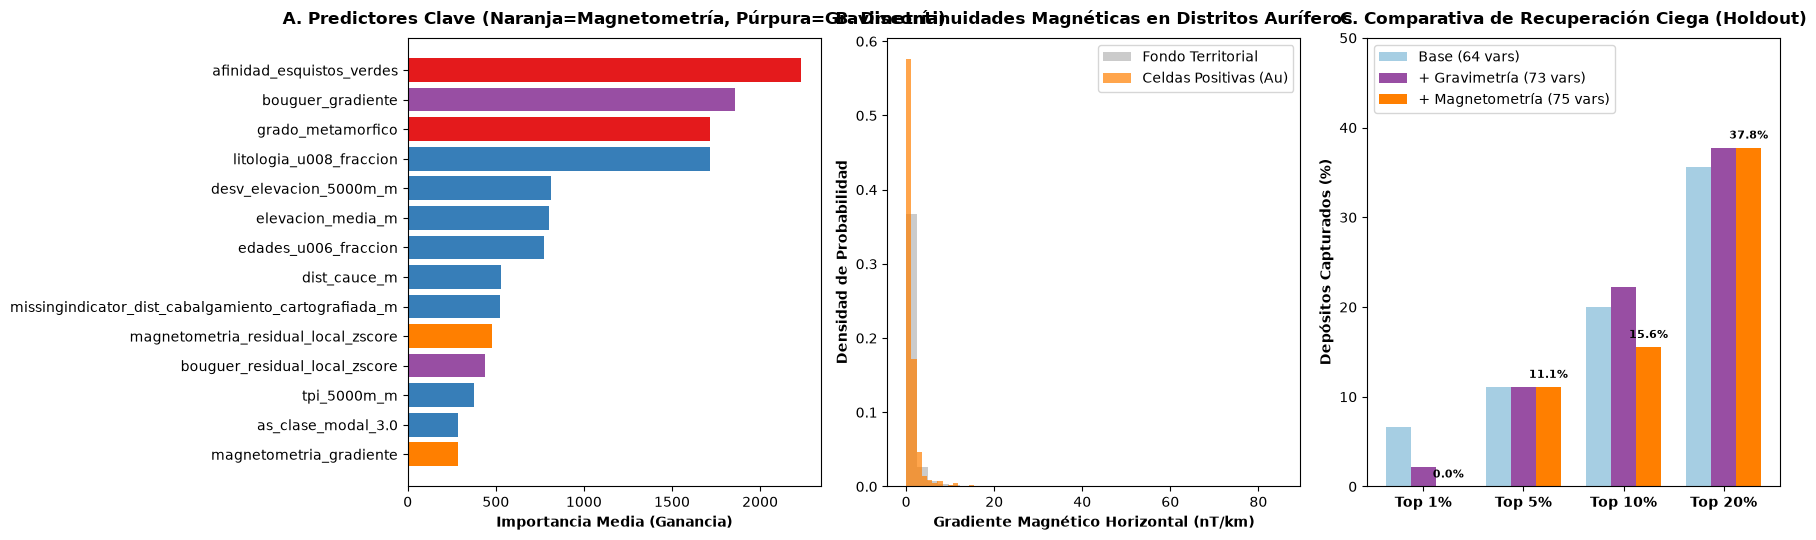

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=100)

# Panel 1: Top 14 Características
ax1 = axes[0]
top14 = df_imp.head(14).iloc[::-1]
col_map = {'Aeromagnetometría': '#ff7f00', 'Gravimetría': '#984ea3', 'Física Superficial': '#e41a1c', 'Original': '#377eb8'}
bar_colors = [col_map[t] for t in top14['tipo']]
ax1.barh(top14['feature'], top14['importance'], color=bar_colors)
ax1.set_xlabel('Importancia Media (Ganancia)', fontweight='bold')
ax1.set_title('A. Predictores Clave (Naranja=Magnetometría, Púrpura=Gravimetría)', fontweight='bold', pad=10)

# Panel 2: Histograma del Gradiente Magnético
ax2 = axes[1]
is_pos = grid.cell_id.isin(set(data.positives.cell_id))
ax2.hist(grid.loc[~is_pos, 'magnetometria_gradiente'], bins=35, density=True, alpha=0.5, color='#999999', label='Fondo Territorial')
ax2.hist(grid.loc[is_pos, 'magnetometria_gradiente'], bins=35, density=True, alpha=0.7, color='#ff7f00', label='Celdas Positivas (Au)')
ax2.set_xlabel('Gradiente Magnético Horizontal (nT/km)', fontweight='bold')
ax2.set_ylabel('Densidad de Probabilidad', fontweight='bold')
ax2.set_title('B. Discontinuidades Magnéticas en Distritos Auríferos', fontweight='bold', pad=10)
ax2.legend()

# Panel 3: Comparativa de Recuperación Ciega
ax3 = axes[2]
met_bars = ['Top 1%', 'Top 5%', 'Top 10%', 'Top 20%']
orig_bars = [3/45*100, 5/45*100, 9/45*100, 16/45*100]
grav_bars = [1/45*100, 5/45*100, 10/45*100, 17/45*100]
mag_bars = [summary_mag_rot['recovery_at_01']*100, summary_mag_rot['recovery_at_05']*100,
            summary_mag_rot['recovery_at_10']*100, summary_mag_rot['recovery_at_20']*100]

x = np.arange(len(met_bars))
w = 0.25
ax3.bar(x - w, orig_bars, width=w, label='Base (64 vars)', color='#a6cee3')
ax3.bar(x, grav_bars, width=w, label='+ Gravimetría (73 vars)', color='#984ea3')
ax3.bar(x + w, mag_bars, width=w, label='+ Magnetometría (75 vars)', color='#ff7f00')
ax3.set_xticks(x)
ax3.set_xticklabels(met_bars, fontweight='bold')
ax3.set_ylabel('Depósitos Capturados (%)', fontweight='bold')
ax3.set_title('C. Comparativa de Recuperación Ciega (Holdout)', fontweight='bold', pad=10)
ax3.set_ylim(0, 50)
for i in range(len(x)):
    ax3.text(x[i] + w, mag_bars[i] + 1, f"{mag_bars[i]:.1f}%", ha='center', fontsize=8, fontweight='bold')
ax3.legend(loc='upper left')

plt.tight_layout()
plt.show()

In [9]:
out_dir = ROOT / "reports" / "reentrenamiento_aeromagnetometria_20261021"
out_dir.mkdir(parents=True, exist_ok=True)

df_export = pd.DataFrame({
    'cell_id': data.grid.cell_id.values,
    'favorability_multigeofisica': score_ens,
    'magnetometria_anomalia_nt': grid['magnetometria_anomalia'].values,
    'magnetometria_gradiente_nt_km': grid['magnetometria_gradiente'].values,
    'magnetometria_residual_local_zscore': grid['magnetometria_residual_local_zscore'].values
})
df_export.to_parquet(out_dir / "favorabilidad_nacional_aeromagnetometria.parquet", index=False)
df_comp_rot.to_csv(out_dir / "comparativa_rotaciones_aeromagnetometria.csv", index=False)
df_mag_stats.to_csv(out_dir / "estadisticas_magnetometria.csv", index=False)
df_imp.to_csv(out_dir / "importancia_variables_aeromagnetometria.csv", index=False)

print(f"✅ Artefactos del modelo multigeofísico guardados en: {out_dir}")

✅ Artefactos del modelo multigeofísico guardados en: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\reentrenamiento_aeromagnetometria_20261021
